In [91]:
from sklearn.datasets import load_breast_cancer
from src.gaussian_mixture import GaussianMixtureMAR
from sklearn.model_selection import train_test_split

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

import torch
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [92]:
import os
from pathlib import Path
R_HOME = Path(r"C:\Users\hu\AppData\Local\Programs\R\R-4.5.3")
assert (R_HOME / "bin" / "R.exe").exists(), "R.exe not found"
assert (R_HOME / "bin" / "x64" / "R.dll").exists(), "R.dll not found"
os.environ["R_HOME"] = str(R_HOME)
os.environ["PATH"] = (
    str(R_HOME / "bin" / "x64")
    + os.pathsep
    + str(R_HOME / "bin")
    + os.pathsep
    + os.environ["PATH"]
)
from src.ampute_mar import AmputeMAR

In [93]:
def ampute_mar_tensor(X, prop=0.2):
    """
    X: complete tensor of shape (n_samples, n_features)
    prop: approximate proportion missing per feature
    Returns:
        X_missing: tensor with NaNs
        mask: True = observed, False = missing
    """
    X_missing = X.clone().float()
    n, p = X.shape

    if p < 2:
        raise ValueError("MAR requires at least two features.")
    if not 0 <= prop <= 1:
        raise ValueError("prop must be between 0 and 1.")

    # generator = torch.Generator(device=X.device)
    # generator.manual_seed(seed)

    # Standardize columns for comparable scales
    mean = X_missing.mean(dim=0)
    std = X_missing.std(dim=0).clamp_min(1e-8)
    Z = (X_missing - mean) / std

    missing = torch.zeros_like(X_missing, dtype=torch.bool)

    for j in range(p):
        # Other features determine missingness in feature j
        predictors = torch.cat([Z[:, :j], Z[:, j+1:]], dim=1)
        score = predictors.mean(dim=1)

        # Convert scores into probabilities
        prob = torch.sigmoid(score)

        # Select approximately prop * n values as missing
        n_missing = round(prop * n)
        if n_missing > 0:
            idx = torch.topk(prob, n_missing).indices
            missing[idx, j] = True

    X_missing[missing] = float("nan")
    return ~missing

In [94]:
def ampute_mar_pd(X, prop=0.2):
    """
    Introduce MAR-like missingness into a complete Pandas DataFrame.

    Parameters
    ----------
    X : pd.DataFrame
        Complete DataFrame of shape (n_samples, n_features).
        All columns must be numeric and contain no missing values.
    prop : float, default=0.2
        Approximate proportion of missing values per feature.
    seed : int, default=42
        Random seed for reproducibility.

    Returns
    -------
    X_missing : pd.DataFrame
        DataFrame with NaN values introduced.
    mask : pd.DataFrame
        Boolean DataFrame: True = observed, False = missing.
    """
    if not isinstance(X, pd.DataFrame):
        raise TypeError("X must be a pandas DataFrame.")

    if X.isna().any().any():
        raise ValueError("X must be complete (no missing values).")

    if not all(pd.api.types.is_numeric_dtype(dtype)
               for dtype in X.dtypes):
        raise TypeError("All columns must be numeric.")

    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError("X must contain only finite values.")

    if not 0 <= prop <= 1:
        raise ValueError("prop must be between 0 and 1.")

    n, p = X.shape

    if p < 2:
        raise ValueError("MAR requires at least two features.")

    # rng = np.random.default_rng(seed)

    # Work with a floating-point copy
    X_missing = X.astype(float).copy()

    # Standardize columns for comparable scales
    values = X_missing.to_numpy()
    mean = values.mean(axis=0)
    std = values.std(axis=0)
    std = np.maximum(std, 1e-8)

    Z = (values - mean) / std

    # True = observed, False = missing
    mask = np.ones((n, p), dtype=bool)

    n_missing = round(prop * n)

    for j in range(p):
        # Other features determine missingness in feature j
        predictors = np.concatenate(
            [Z[:, :j], Z[:, j + 1:]], axis=1
        )
        score = predictors.mean(axis=1)

        # Convert scores into probabilities
        probabilities = 1 / (1 + np.exp(-np.clip(score, -500, 500)))

        # Select approximately prop * n values as missing
        if n_missing > 0:
            idx = np.argsort(probabilities)[-n_missing:]
            mask[idx, j] = False

    # Introduce missing values
    X_missing.iloc[:, :] = X_missing.where(mask)

    return torch.tensor(mask)

In [95]:
class Clustering(GaussianMixtureMAR):

    def __init__(self,
                 X,
                 M,
                 n_clusters=2,
                 k_range=None,
                 criterion="bic", 
                 cov_type='uni_diag', 
                 max_iter=100, 
                 tol=0.000001, 
                 eps=0.000001, 
                 reg_covar=0.000001, 
                 n_init=20, 
                 _k_tol=1, 
                 device="cpu", 
                 verbose=False):
        super().__init__(k_range, criterion, cov_type, max_iter, tol, eps, reg_covar, n_init, _k_tol, device, verbose)
        self.n_clusters = n_clusters
        self.model = self._fit(X, M)

    def _top_k_components(self, X, M=None, k=1):
        """
        Find which cluster each observation is mostly likely from
        """
        if M is None:
            M = torch.ones_like(X, device=X.device)
        _, indices = torch.topk(self.log_prob_N_K_D(X, M).sum(dim=2), dim=1, k=k)
        return indices

    def _fit(self, X, M):
        self.fit(X, M)
        return self.best_model

    def _cluster_centers(self):
        """
        Cluster Gaussian centers using train data
        """
        mu_np = self.model.mu.detach().cpu().numpy()
        kmeans = KMeans(n_clusters=self.n_clusters, n_init=20, random_state=123)
        return kmeans.fit_predict(mu_np)

    def cluster_through_centers(self, X, M):
        idx = self._top_k_components(X, M, k=1)
        self.center_labels = self._cluster_centers()
        return [self.center_labels[idx[i]].item() for i in range(len(idx))]

    def cluster_by_topk(self, X, M, k=3):
        idx = self._top_k_components(X, M, k)
        return idx

    def cluster_by_logprob(self, X, M):
        return self.log_prob_x_m(X, M)


# Simulation

In [96]:
# Simulate data
n = 5000
d = 30
norm1 = torch.distributions.MultivariateNormal(loc=torch.tensor([0.0, 0.0]), covariance_matrix=torch.tensor([[1.0,0.5], [0.5,1.0]]))
Y1 = norm1.sample((n,))
norm2 = torch.distributions.MultivariateNormal(loc=torch.tensor([5.0, 5.0]), covariance_matrix=torch.tensor([[1.0,0.5], [0.5,1.0]]))
Y2 = norm2.sample((int(n/2),))

U = torch.distributions.Uniform(0,1).sample((2,30))

In [97]:
X = Y1 @ U
idx = torch.randperm(n)[:int(n/2)]
X[idx] = Y2 @ U
X += torch.randn_like(X)

In [98]:
am = AmputeMAR()
M = am.ampute(X)[1]

In [99]:
true_labels = torch.ones(n)
true_labels[idx] = 2

Default of GMMMAR gives shared covariances of each center.

In [100]:
cl = Clustering(X, M, k_range=(0,20))
topk_ind = cl.cluster_by_logprob(X, M)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=123)
labels_topk = kmeans.fit_predict(topk_ind)

labels_centers = cl.cluster_through_centers(X, M)

pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

In [101]:
print(cl.log_prob_x(X).sum())

tensor(-228766.5469)


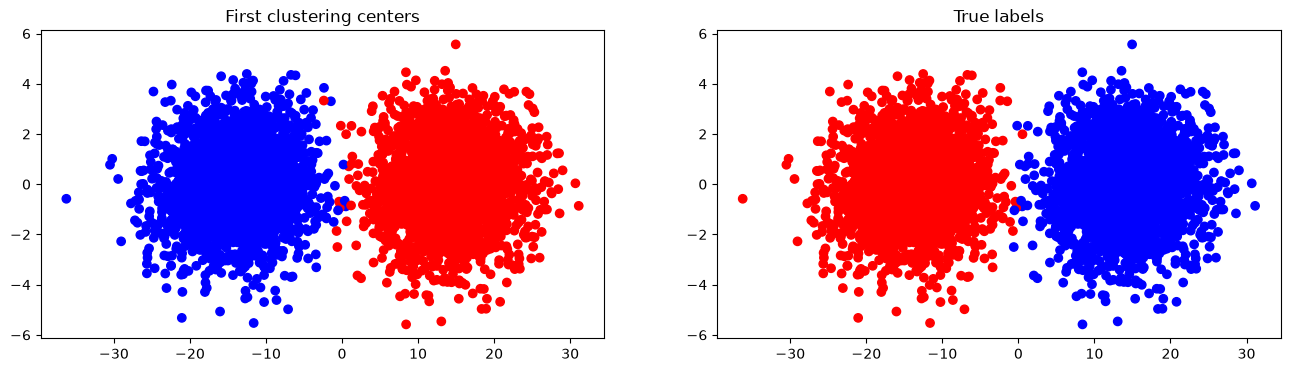

In [102]:
_, axes = plt.subplots(1,2, figsize=(16,4))
axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[0].set_title('First clustering centers')

# axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_topk, 'red', 'blue'))
# axes[1].set_title('By logprob (N, K)')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(true_labels==1, 'red', 'blue'))
axes[1].set_title('True labels')

plt.show()

C:\Users\hu\AppData\Local\Temp\ipykernel_32788\2543044245.py:8: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


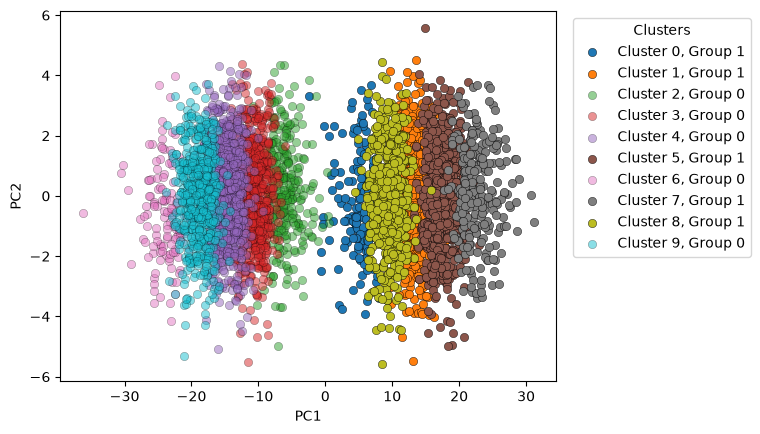

In [103]:
labels = cl.which_cluster(X, M)

cmap = plt.get_cmap("tab10", len(np.unique(labels)))

for k in np.unique(labels):
    mask = labels == k
    a = int(k in np.where(cl.center_labels==1)[0])
    plt.scatter(
        pcs[mask, 0],
        pcs[mask, 1],
        label=f"Cluster {k}, Group {a}",
        alpha= (a + 1) / 2,
        c=cmap(k),
        edgecolors="black",
        linewidths=0.3
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Clusters", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

In [104]:
cl = Clustering(X, M, k_range=(0,20))
topk_ind = cl.cluster_by_logprob(X, M)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=123)
labels_topk = kmeans.fit_predict(topk_ind)


labels_centers = cl.cluster_through_centers(X, M)

pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

In [105]:
print(cl.log_prob_x(X).sum())

tensor(-229263.3750)


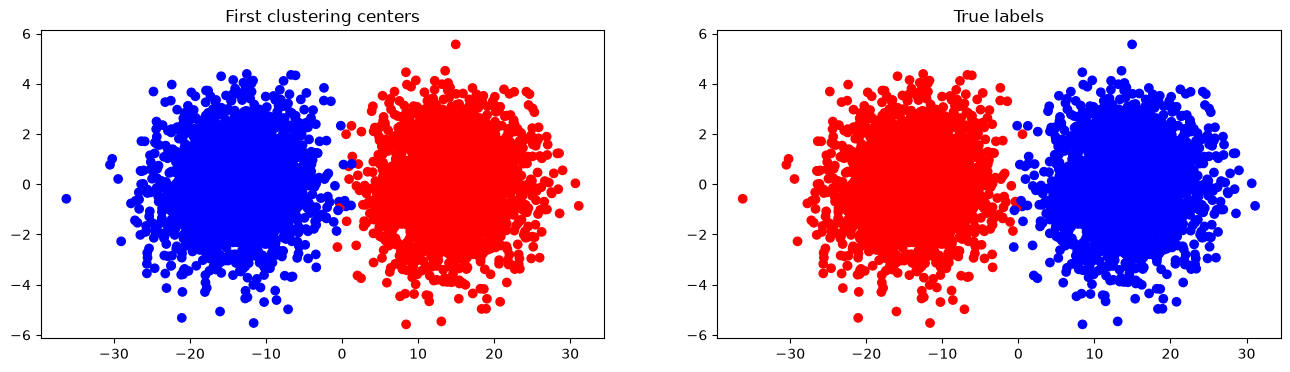

In [106]:
_, axes = plt.subplots(1,2, figsize=(16,4))

axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[0].set_title('First clustering centers')

# axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_topk, 'red', 'blue'))
# axes[1].set_title('By logprob (N, K)')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(true_labels==1, 'red', 'blue'))
axes[1].set_title('True labels')

plt.show()

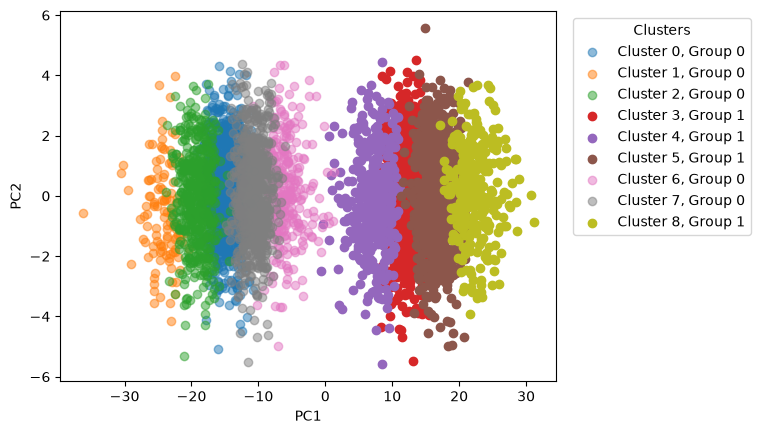

In [107]:
labels = cl.which_cluster(X, M)

for k in np.unique(labels):
    mask = labels == k
    a = int(k in np.where(cl.center_labels==1)[0])
    plt.scatter(
        pcs[mask, 0],
        pcs[mask, 1],
        label=f"Cluster {k}, Group {a}",
        alpha= (a + 1) / 2
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Clusters", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

# Breast Cancer Data

In [108]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

X = torch.tensor(X.to_numpy())
# M = ampute_mar_tensor(X)

am = AmputeMAR()
M = am.ampute(X)[1]

# Xtrain, Xtest, Mtrain, Mtest, ytrain, ytest = train_test_split(
#     X, M, y, test_size=0.25, stratify=y, random_state=42)

# Mtrain = Mtrain.int()
# Mtest = Mtest.int()

In [109]:
cl = Clustering(X, M, k_range=(0,20))
topk_ind = cl.cluster_by_logprob(X, M)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=123)
labels_topk = kmeans.fit_predict(topk_ind)

labels_centers = cl.cluster_through_centers(X, M)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.numpy())
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)

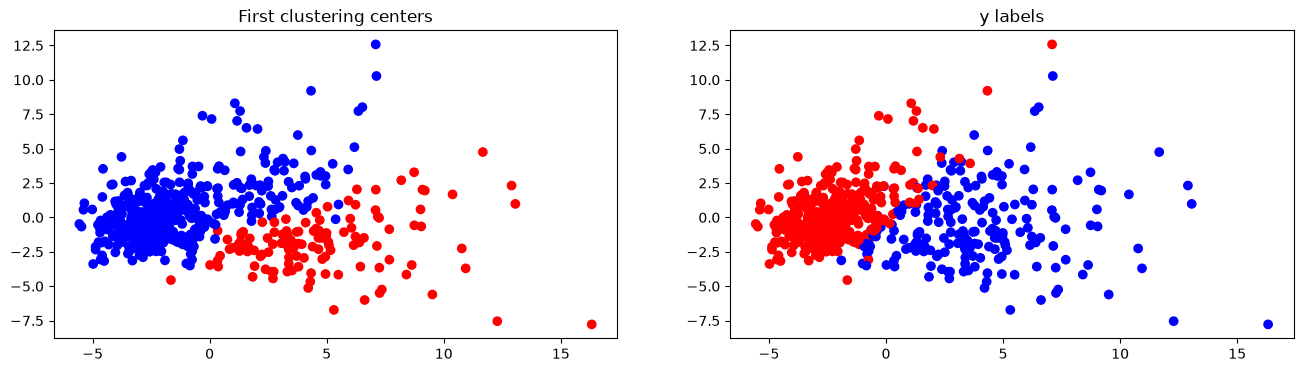

In [111]:
_, axes = plt.subplots(1,2, figsize=(16,4))

axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[0].set_title('First clustering centers')

# axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_topk, 'red', 'blue'))
# axes[1].set_title('By topk')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(y==1, 'red', 'blue'))
axes[1].set_title('y labels')

plt.show()

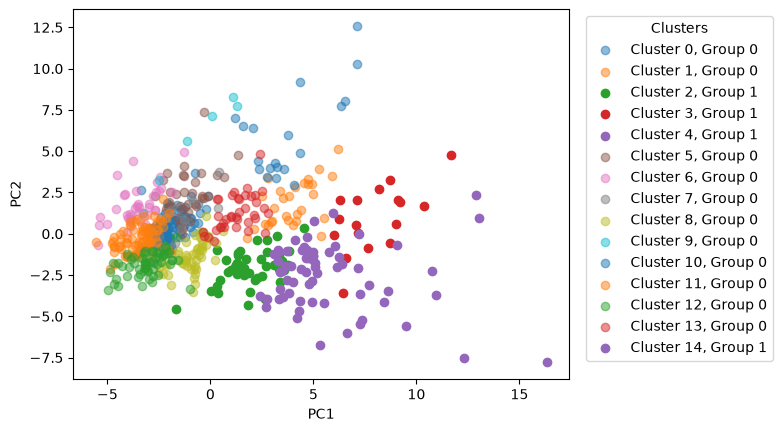

In [112]:
labels = cl.which_cluster(X, M)

for k in np.unique(labels):
    mask = labels == k
    a = int(k in np.where(cl.center_labels==1)[0])
    plt.scatter(
        pcs[mask, 0],
        pcs[mask, 1],
        label=f"Cluster {k}, Group {a}",
        alpha= (a + 1) / 2
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Clusters", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()